# Rooftop solar and household electricity use
UC Berkeley ML Capstone · Assignment 20.1

Can half-hour meter history and calendar features support next-day forecasts of gross solar generation and total demand for the same homes? This notebook audits the meter panel, characterizes the timing and variation of both targets, and evaluates one pooled linear regression against weekly persistence. Battery dispatch motivates the analysis. See the [README](../README.md) and [data preparation notes](../DATA_PREPARATION.md).

In [1]:
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.linear_model import LinearRegression

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
mode = os.environ.get("AUSGRID_MODE", "auto")
assert mode in {"auto", "sample", "full"}
full_path = root / "data/processed/ausgrid_intervals.csv.gz"
full = mode == "full" or (mode == "auto" and full_path.exists())
path = full_path if full else root / "data/sample/ausgrid_sample.csv"
validation_start, test_start = map(pd.Timestamp, (
    ("2011-07-01", "2012-07-01") if full else ("2012-07-15", "2012-07-22")
))
first_day, last_day = (
    ("2010-07-01", "2013-06-30") if full else ("2012-07-01", "2012-07-28")
)
dates = pd.date_range(first_day, last_day)
audit = json.loads((root / "data/ausgrid_audit.json").read_text())
dst_dates = pd.to_datetime([
    day for year in audit["years"].values()
    for day in year["source_dates_with_dst_transitions_excluded"]
]).intersection(dates)
expected_dates = dates.difference(dst_dates)
targets = ["solar_kwh", "load_kwh"]
labels = ["Gross solar", "Household load"]
colors = ["#b76915", "#245985"]
plt.rcParams.update({
    "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True, "axes.axisbelow": True,
    "grid.alpha": 0.22, "font.size": 10,
})
print(f"{'Full archive' if full else 'Two-home example'} | {path.name} | {path.stat().st_size:,} bytes")

Full archive | ausgrid_intervals.csv.gz | 78,488,965 bytes


## Meter preparation and data quality

The data preparation code reshapes three annual files, combines general and controlled consumption under the documented channel-availability rule, and converts Sydney interval endings to UTC interval starts. Six daylight-saving transition dates are omitted because the source supplies 48 slots even on offset-change days. Blank, invalid and flagged readings are audited upstream. The processed panel is checked independently for keys, invalid values, complete Sydney days and dates absent from the expected grid. A missing day remains missing.

The plots below describe all valid complete days, including the later evaluation years. Forecast features and weights use the chronological information rules documented in the model section.

In [2]:
from collections import Counter

source_audit = pd.DataFrame([
    {"Source year starts": year, "Usable intervals": entry["usable_intervals"],
     "Missing GC channel-days": entry["counts"].get("missing_GC_days", 0),
     "Missing GG channel-days": entry["counts"].get("missing_GG_days", 0),
     "Missing CL channel-days": entry["counts"].get("missing_CL_days", 0),
     "Flagged household-days dropped": entry["counts"].get("flagged_complete_channel_days_excluded", 0)}
    for year, entry in audit["years"].items()
]).set_index("Source year starts")
display(source_audit)

from tempfile import TemporaryDirectory

def household_frames(path):
    # The full export is ordered by source year, then household. Partition
    # on household ID so all years for a home can be audited together.
    with TemporaryDirectory(prefix="ausgrid-") as scratch:
        parts = {}
        for number, chunk in enumerate(pd.read_csv(path, chunksize=400_000)):
            assert chunk.household_id.notna().all(), "Missing household ID."
            for bucket, block in chunk.groupby(chunk.household_id % 16):
                part = Path(scratch) / f"{bucket}-{number}.pkl"
                block.to_pickle(part)
                parts.setdefault(bucket, []).append(part)
        for bucket in sorted(parts):
            frame = pd.concat([pd.read_pickle(p) for p in parts[bucket]], ignore_index=True)
            yield from frame.groupby("household_id")

def model_matrix(day, slot, lag):
    time = slot * (2 * np.pi / 48)
    year = (day.day_of_year.to_numpy() - 1) * (2 * np.pi / 365.25)
    return np.column_stack([
        lag, np.sin(time), np.cos(time), np.sin(2 * time), np.cos(2 * time),
        np.sin(year), np.cos(year), day.day_of_week >= 5,
    ]).astype("float32")

,Usable intervals,Missing GC channel-days,Missing GG channel-days,Missing CL channel-days,Flagged household-days dropped
Source year starts,,,,,
2010,5227200,0,0,0,0
2011,5230992,0,0,170,52
2012,5182368,81,81,651,284


In [3]:
quality = Counter()
daily_parts, coverage_parts, profile_parts, tail_parts = [], [], [], []
train_x, train_y = [], []
evaluation = {"Validation": [], "Test": []}
example = None

for household, frame in household_frames(path):
    stamp = pd.to_datetime(frame.interval_start_utc, utc=True, errors="coerce")
    values = frame[targets].to_numpy()
    issues = {
        "Missing fields": int(frame.isna().sum().sum()),
        "Invalid timestamps": int(stamp.isna().sum()),
        "Duplicate household/UTC keys": int(stamp.duplicated().sum()),
        "Non-finite meter values": int((~np.isfinite(values)).sum()),
        "Negative meter values": int((values < 0).sum()),
        "Off-grid timestamps": int(stamp.ne(stamp.dt.floor("30min")).sum()),
    }
    quality.update(issues)
    quality["Rows"] += len(frame)
    assert not any(issues.values()), (household, issues)
    local = stamp.dt.tz_convert("Australia/Sydney").dt.tz_localize(None)
    frame = frame.assign(
        day=local.dt.normalize(),
        slot=2 * local.dt.hour + local.dt.minute // 30,
    ).sort_values(["day", "slot"])
    assert frame.day.isin(expected_dates).all()
    grouped = frame.groupby("day")
    sizes = grouped.slot.agg(["size", "nunique"])
    complete = sizes.index[sizes["size"].eq(48) & sizes["nunique"].eq(48)]
    coverage_parts.append(sizes["size"].reindex(expected_dates, fill_value=0).rename(household))
    quality["Partial or repeated-slot days"] += len(sizes) - len(complete)
    frame = frame.loc[frame.day.isin(complete)].copy()
    frame["margin"] = frame.solar_kwh - frame.load_kwh
    frame["surplus"] = frame.margin.clip(lower=0)
    frame["surplus_slot"] = frame.margin.gt(0)
    frame["weekend"] = frame.day.dt.day_of_week.ge(5)
    frame["month"] = frame.day.dt.month

    daily_parts.append(frame.groupby("day")[targets + ["surplus", "surplus_slot"]].sum().assign(home=household))
    profile_parts.append(frame.groupby(["month", "weekend", "slot"])[targets + ["surplus_slot"]].agg(["sum", "size"]))
    if household == 1:
        first = frame.day.min()
        example = frame.loc[frame.day.lt(first + pd.Timedelta(days=7))].assign(home=household)

    for target in targets:
        readings = frame[target]
        positive = readings[readings.gt(0)]
        q1, q99, q3 = positive.quantile([0.25, 0.99, 0.75])
        high_fence = q3 + 1.5 * (q3 - q1)
        peak = readings.idxmax()
        tail_parts.append({
            "home": household, "target": target, "zero": readings.eq(0).sum(),
            "positive": len(positive), "high flags": positive.gt(high_fence).sum(),
            "positive p99": q99, "maximum": readings.max(),
            "peak day": frame.loc[peak, "day"], "peak slot": frame.loc[peak, "slot"],
        })

    # Shift the join key on complete local days. A missing date cannot turn
    # a seven-calendar-day lag into a seven-observation lag.
    previous = frame[["day", "slot", *targets]].copy()
    previous["day"] += pd.Timedelta(days=7)
    pairs = frame[["day", "slot", *targets]].merge(
        previous, on=["day", "slot"], suffixes=("", "_lag7"), validate="one_to_one"
    )
    day = pd.DatetimeIndex(pairs.day)
    slot = pairs.slot.to_numpy()
    lag = pairs[[f"{target}_lag7" for target in targets]].to_numpy(dtype="float32")
    actual = pairs[targets].to_numpy(dtype="float32")
    design = model_matrix(day, slot, lag)
    train = day < validation_start
    train_x.append(design[train])
    train_y.append(actual[train])
    for name, mask in {
        "Validation": (day >= validation_start) & (day < test_start),
        "Test": day >= test_start,
    }.items():
        evaluation[name].append((design[mask], actual[mask], slot[mask]))

coverage = pd.concat(coverage_parts, axis=1)
quality["Expected household-days excluding DST dates"] = coverage.size
quality["Entirely absent household-days"] = int(coverage.eq(0).sum().sum())
quality["Households"] = coverage.shape[1]
daily = pd.concat(daily_parts).sort_index()
profiles = pd.concat(profile_parts).groupby(level=["month", "weekend", "slot"]).sum()
tails = pd.DataFrame(tail_parts)
display(pd.Series(quality, name="Count").to_frame())
display(daily[targets].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(2))
if full:
    assert quality["Rows"] == sum(y["usable_intervals"] for y in audit["years"].values())
    assert quality["Households"] == 300

,Count
Missing fields,0
Invalid timestamps,0
Duplicate household/UTC keys,0
Non-finite meter values,0
Negative meter values,0
Off-grid timestamps,0
Rows,15640560
Partial or repeated-slot days,0
Expected household-days excluding DST dates,327000
Entirely absent household-days,1155


,solar_kwh,load_kwh
count,325845.00,325845.00
mean,5.82,18.23
std,4.95,10.84
min,0.00,0.00
1%,0.00,2.64
25%,2.99,10.56
50%,4.81,15.89
75%,7.25,23.45
95%,13.40,38.19
99%,25.55,54.69


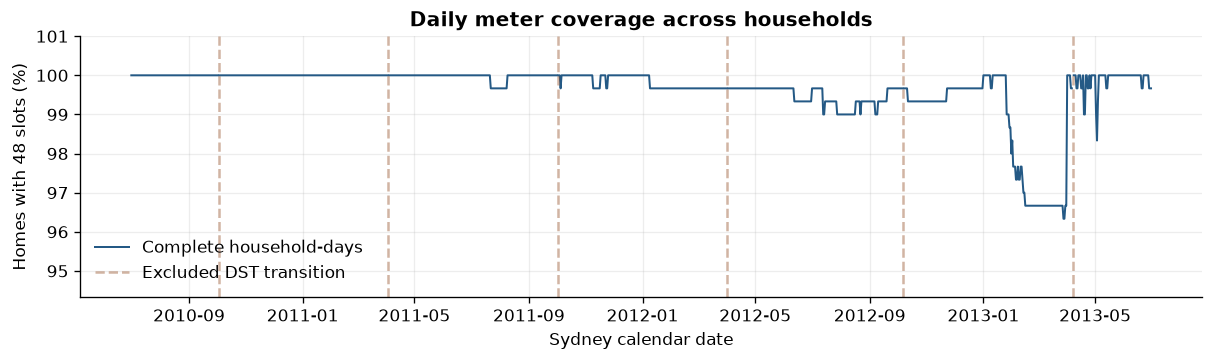

**Coverage.** 1,155 expected household-days are entirely absent across 473 Sydney dates and 45 homes, after setting aside the 6 transition dates. The raw audit counts missing channels separately. Several channel problems can affect one household-day, so those columns cannot be summed to estimate coverage loss.

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.9), layout="constrained")
available = coverage.eq(48).mean(axis=1).reindex(dates) * 100
ax.plot(available, color=colors[1], linewidth=1.2, label="Complete household-days")
for i, date in enumerate(dst_dates):
    ax.axvline(date, color="#9b5a33", alpha=.45, linestyle="--",
               label="Excluded DST transition" if i == 0 else None)
ax.set(title="Daily meter coverage across households", ylabel="Homes with 48 slots (%)",
       xlabel="Sydney calendar date", ylim=(min(available.min() - 2, 96), 101))
ax.legend(loc="lower left", frameon=False)
plt.show()

missing = coverage.eq(0).sum(axis=1)
display(Markdown(
    f"**Coverage.** {missing.sum():,} expected household-days are entirely absent across "
    f"{missing.gt(0).sum():,} Sydney dates and {coverage.eq(0).any().sum():,} homes, "
    f"after setting aside the {len(dst_dates)} transition dates. "
    "The raw audit counts missing channels separately. Several channel problems can affect one household-day, "
    "so those columns cannot be summed to estimate coverage loss."
))

## Daily rhythms and daylight surplus

Profiles average complete household-intervals. The margin is gross PV minus load within the same half-hour. A positive margin approximates energy available to charge a battery before power limits, efficiency, and state of charge are applied.

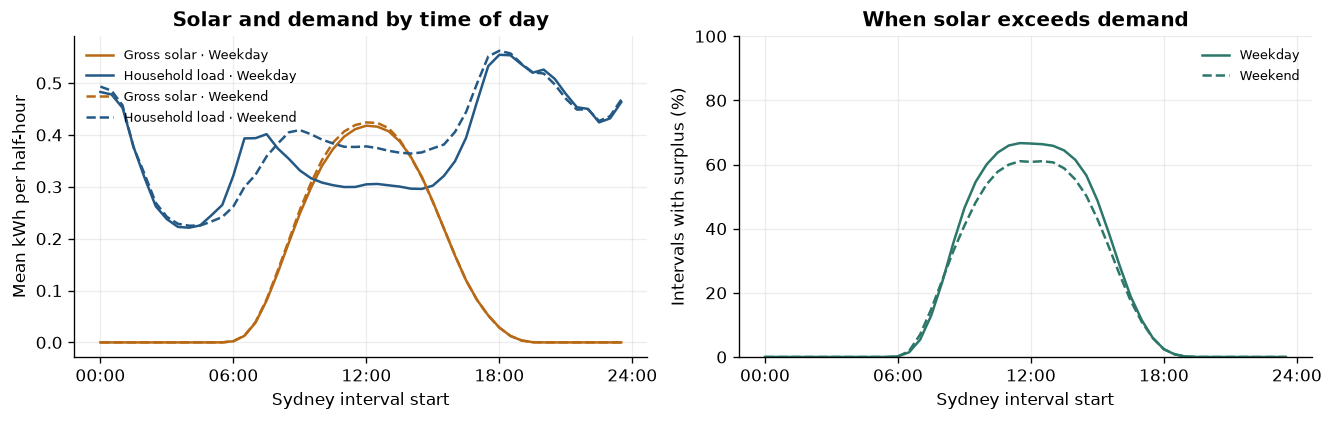

**Timing.** Mean PV peaks at 12:00 and mean demand peaks at 18:00 Sydney time. Average daily use is 17.95 kWh on weekdays and 18.94 kWh on weekends. PV exceeds load in 19.8% of intervals. These intervals identify when solar charging is possible.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained", sharex=True)
by_type = profiles.groupby(level=["weekend", "slot"]).sum()
for flag, line, name in [(False, "-", "Weekday"), (True, "--", "Weekend")]:
    block = by_type.xs(flag)
    for target, label, color in zip(targets, labels, colors):
        axes[0].plot(block.index / 2, block[target]["sum"] / block[target]["size"],
                     color=color, linestyle=line, label=f"{label} · {name}")
    margin = block["surplus_slot"]["sum"] / block["surplus_slot"]["size"]
    axes[1].plot(block.index / 2, 100 * margin, color="#2c7769", linestyle=line, label=name)
for ax in axes:
    ax.set(xlabel="Sydney interval start", xticks=[0, 6, 12, 18, 24],
           xticklabels=["00:00", "06:00", "12:00", "18:00", "24:00"])
    ax.legend(frameon=False, fontsize=8)
axes[0].set(title="Solar and demand by time of day", ylabel="Mean kWh per half-hour")
axes[1].set(title="When solar exceeds demand", ylabel="Intervals with surplus (%)", ylim=(0, 100))
plt.show()

combined = profiles.groupby(level="slot").sum()
mean_profile = pd.DataFrame({target: combined[target]["sum"] / combined[target]["size"] for target in targets})
def clock(slot):
    return f"{slot // 2:02d}:{30 * (slot % 2):02d}"

peaks = mean_profile.idxmax()
weekday_totals = daily.groupby(daily.index.day_of_week >= 5).load_kwh.mean()
surplus_fraction = daily.surplus_slot.sum() / (48 * len(daily))
display(Markdown(
    f"**Timing.** Mean PV peaks at {clock(peaks.solar_kwh)} and mean demand peaks at "
    f"{clock(peaks.load_kwh)} Sydney time. Average daily use is {weekday_totals.loc[False]:.2f} kWh "
    f"on weekdays and {weekday_totals.loc[True]:.2f} kWh on weekends. PV exceeds load in "
    f"{surplus_fraction:.1%} of intervals. These intervals identify when solar charging is possible."
))

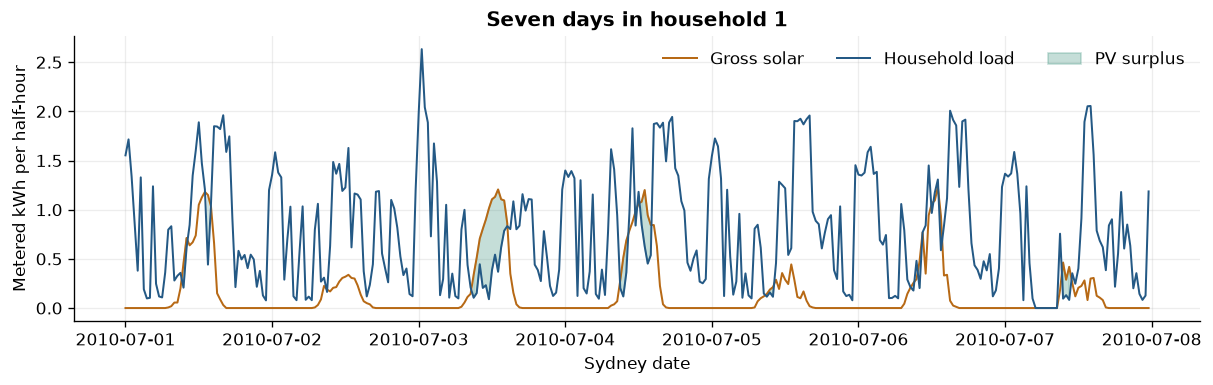

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.1), layout="constrained")
example_time = example.day + pd.to_timedelta(example.slot * 30, unit="min")
for target, label, color in zip(targets, labels, colors):
    ax.plot(example_time, example[target], color=color, linewidth=1.2, label=label)
ax.fill_between(example_time, example.solar_kwh, example.load_kwh,
                where=example.margin.gt(0), color="#4c9b88", alpha=.32, label="PV surplus")
ax.set(title=f"Seven days in household {example.home.iloc[0]}", xlabel="Sydney date",
       ylabel="Metered kWh per half-hour")
ax.legend(frameon=False, ncol=3)
plt.show()

The example shows how the cohort-average curves smooth over individual demand spikes and changing solar profiles. The shaded surplus varies across individual intervals, which is the resolution a dispatch schedule would need.

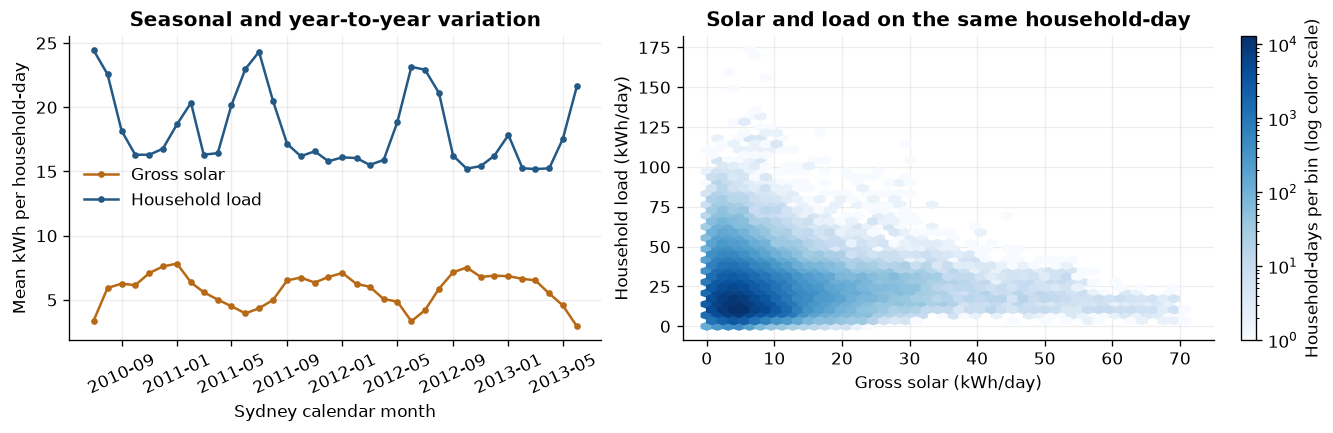

,solar_kwh,load_kwh
day,,
Autumn,5.30,16.82
Spring,6.73,16.40
Summer,6.94,17.00
Winter,4.34,22.62


**Relationship.** Daily solar and load have pooled Pearson r = 0.052. After removing each household's average from both series, r = -0.118. These are descriptive associations. The panel combines homes with different system sizes and usage habits, and the seasonal table uses Australian seasons represented in the selected data.

In [7]:
months = daily.groupby(daily.index.to_period("M"))[targets].mean()
monthly_dates = months.index.to_timestamp()
homes = daily.groupby("home")[targets].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for target, label, color in zip(targets, labels, colors):
    axes[0].plot(monthly_dates, months[target], marker="o", markersize=3, color=color, label=label)
axes[0].set(title="Seasonal and year-to-year variation", ylabel="Mean kWh per household-day",
            xlabel="Sydney calendar month")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(frameon=False)
points = axes[1].hexbin(daily.solar_kwh, daily.load_kwh, gridsize=45, bins="log", mincnt=1,
                       cmap="Blues")
axes[1].set(title="Solar and load on the same household-day",
            xlabel="Gross solar (kWh/day)", ylabel="Household load (kWh/day)")
fig.colorbar(points, ax=axes[1], label="Household-days per bin (log color scale)")
plt.show()

season = daily.groupby(daily.index.month.map(
    {12:"Summer", 1:"Summer", 2:"Summer", 3:"Autumn", 4:"Autumn", 5:"Autumn",
     6:"Winter", 7:"Winter", 8:"Winter", 9:"Spring", 10:"Spring", 11:"Spring"}
))[targets].mean()
correlation = daily[targets].corr().iloc[0, 1]
centered = daily[targets] - daily.groupby("home")[targets].transform("mean")
within_correlation = centered.corr().iloc[0, 1]
display(season.round(2))
display(Markdown(
    f"**Relationship.** Daily solar and load have pooled Pearson r = {correlation:.3f}. After removing "
    f"each household's average from both series, r = {within_correlation:.3f}. These are descriptive "
    "associations. The panel combines homes with different system sizes and usage habits, and the "
    "seasonal table uses Australian seasons represented in the selected data."
))

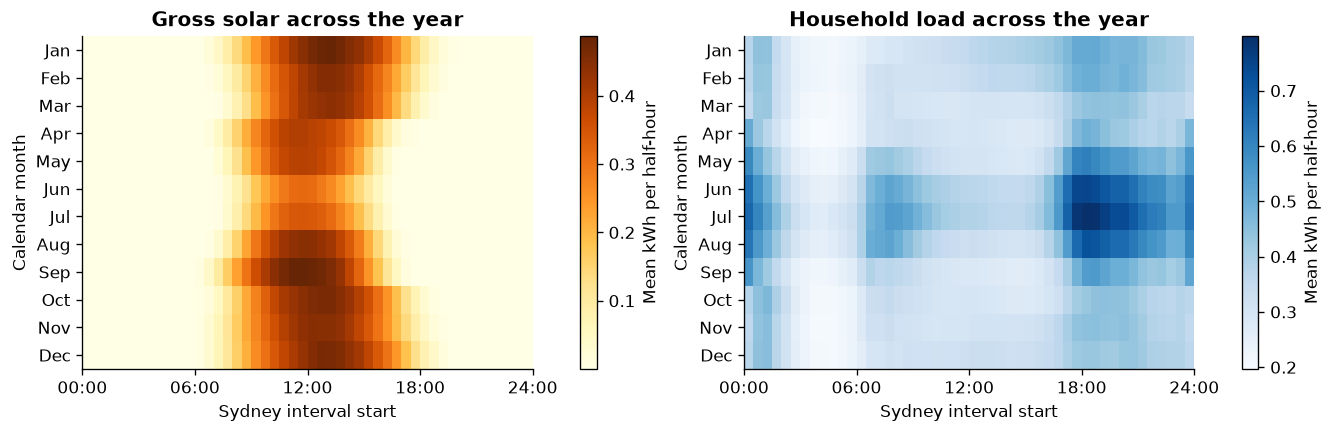

The month-by-time profiles show when PV is available and how the demand peaks move across the calendar. Months outside the selected window appear blank. The timing is in Sydney wall-clock time, so seasonal sunlight and daylight-saving shifts can both affect these patterns.

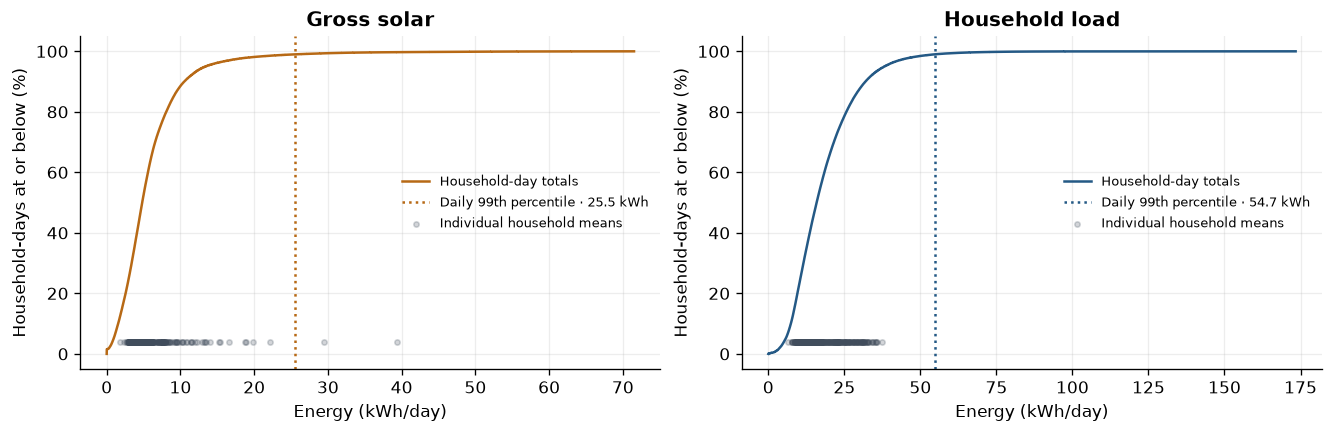

,zero,positive,high flags,zero share (%),high share of positive (%)
target,,,,,
load_kwh,29696,15610864,1406364,0.19,9.01
solar_kwh,8466059,7174501,3991,54.13,0.06


,min,median,max
target,,,
load_kwh,0.633,2.03,4.130
solar_kwh,0.331,0.60,4.106


,target,home,peak day,maximum,Sydney interval start
199,load_kwh,85,2012-01-09,7.805,19:30
424,solar_kwh,75,2012-02-14,4.419,12:30


**Tails.** Solar is zero in 54.1% of intervals. For each home and target, the upper Tukey fence (Q3 + 1.5 × IQR) is estimated on positive readings so night zeros do not define the solar tail. Flags are diagnostic only. Extreme intervals remain in the analysis and model because large values can be physically meaningful. The data available here do not establish an equipment-specific plausibility limit.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
month_slots = profiles.groupby(level=["month", "slot"]).sum()
for ax, target, label, cmap in zip(axes, targets, labels, ["YlOrBr", "Blues"]):
    matrix = (month_slots[target]["sum"] / month_slots[target]["size"]).unstack("slot")
    matrix = matrix.reindex(range(1, 13))
    heat = ax.imshow(matrix, extent=(0, 24, 12.5, .5), aspect="auto", cmap=cmap)
    ax.set(title=f"{label} across the year", xlabel="Sydney interval start", ylabel="Calendar month",
           xticks=[0, 6, 12, 18, 24], xticklabels=["00:00", "06:00", "12:00", "18:00", "24:00"],
           yticks=range(1, 13), yticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax.grid(False)
    fig.colorbar(heat, ax=ax, label="Mean kWh per half-hour")
plt.show()
display(Markdown(
    "The month-by-time profiles show when PV is available and how the demand peaks move across "
    "the calendar. Months outside the selected window appear blank. The timing is in Sydney "
    "wall-clock time, so seasonal sunlight and daylight-saving shifts can both affect these patterns."
))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, target, label, color in zip(axes, targets, labels, colors):
    population = daily[target].sort_values().to_numpy()
    ecdf = np.arange(1, len(population) + 1) / len(population)
    ax.step(population, ecdf * 100, color=color, label="Household-day totals")
    p99 = np.quantile(population, .99)
    ax.axvline(p99, color=color, linestyle=":", label=f"Daily 99th percentile · {p99:.1f} kWh")
    ax.scatter(homes[target], np.full(len(homes), 4), s=10, alpha=.23, color="#414d5c",
               label="Individual household means")
    ax.set(title=label, xlabel="Energy (kWh/day)", ylabel="Household-days at or below (%)")
    ax.legend(frameon=False, fontsize=8, loc="center right")
plt.show()

tail_totals = tails.groupby("target")[["zero", "positive", "high flags"]].sum()
tail_totals["zero share (%)"] = 100 * tail_totals.zero / (tail_totals.zero + tail_totals.positive)
tail_totals["high share of positive (%)"] = 100 * tail_totals["high flags"] / tail_totals.positive
display(tail_totals.round(2))
display(tails.groupby("target")["positive p99"].agg(["min", "median", "max"]).round(3))
display(tails.loc[tails.groupby("target")["maximum"].idxmax(),
                  ["target", "home", "peak day", "peak slot", "maximum"]].assign(
                      **{"Sydney interval start": lambda t: t["peak slot"].map(clock)}
                  ).drop(columns="peak slot"))
display(Markdown(
    f"**Tails.** Solar is zero in {tail_totals.loc['solar_kwh', 'zero share (%)']:.1f}% of intervals. "
    "For each home and target, the upper Tukey fence (Q3 + 1.5 × IQR) is estimated on positive "
    "readings so night zeros do not define the solar tail. Flags are diagnostic only. Extreme "
    "intervals remain in the analysis and model because large values can be physically meaningful. "
    "The data available here do not establish an equipment-specific plausibility limit."
))

## Day-ahead linear regression

Fit one pooled multi-output ordinary least squares model with the same feature set for both targets. Inputs are both meter readings from the same household's corresponding Sydney half-hour seven calendar days earlier, cyclic clock features (first two daily harmonics), annual sine and cosine, and a weekend flag. These variables are known at the prior day's 18:00 cutoff. No target-day readings, estimated weather, feature scaling, or hyperparameter search enter the fit. Negative predictions are clipped to zero. Both methods score only complete target days with complete weekly lag days. Forecasts may use recent observed meter values from an earlier date in the evaluation period, as they would in operation.

On the full panel the three source years form train, validation and test in that order. The sample uses two weeks for training and one week each for validation and test. The initial seven days in training have no lag. Within each period, MAE measures typical interval error and RMSE emphasizes larger errors. Both are in kWh per half-hour.

Training through 2011-06-30 | 5,097,600 intervals


,Period,Method,Target,Intervals,MAE,RMSE
0,Validation,Linear regression,Gross solar,5201424,0.0635,0.1448
1,Validation,Linear regression,Household load,5201424,0.2358,0.3868
2,Validation,Weekly persistence,Gross solar,5201424,0.0633,0.1604
3,Validation,Weekly persistence,Household load,5201424,0.2254,0.4418
4,Test,Linear regression,Gross solar,5146896,0.0612,0.1401
5,Test,Linear regression,Household load,5146896,0.2361,0.3889
6,Test,Weekly persistence,Gross solar,5146896,0.0593,0.1530
7,Test,Weekly persistence,Household load,5146896,0.2252,0.4473


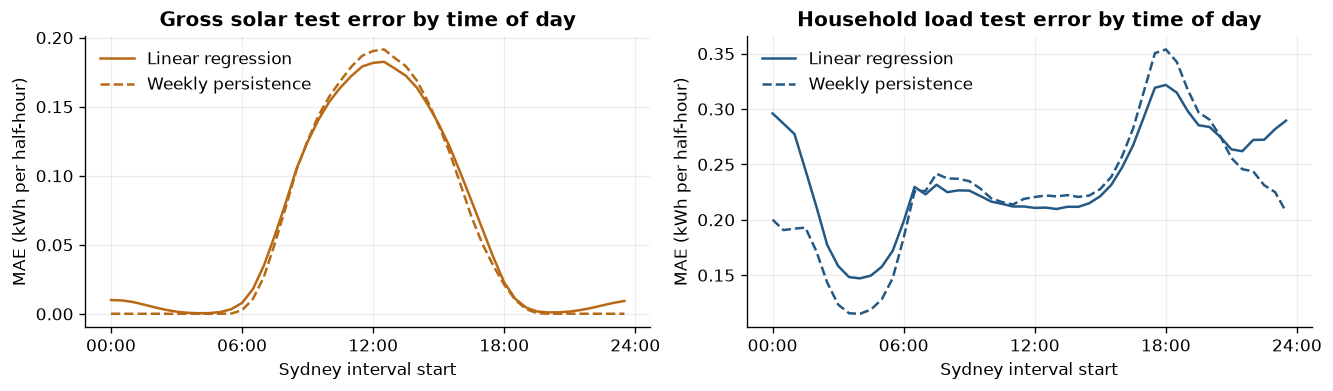

**Held-out comparison.** Relative to weekly persistence, MAE changes by +3.3% for gross solar and +4.9% for household load. Time-of-day error profiles show whether the changes occur during solar production and high-demand periods. These scores estimate performance on previously observed homes with an available weekly lag.

In [9]:
X, y = np.concatenate(train_x), np.concatenate(train_y)
train_x.clear()
train_y.clear()
model = LinearRegression().fit(X, y)
print(f"Training through {(validation_start - pd.Timedelta(days=1)).date()} | {len(y):,} intervals")
del X, y

metric_rows, error_profiles = [], []
for split, blocks in evaluation.items():
    for method in ["Linear regression", "Weekly persistence"]:
        total_absolute = np.zeros(2)
        total_squared = np.zeros(2)
        per_slot = np.zeros((48, 2))
        slot_counts = np.zeros(48)
        for design, actual, slot in blocks:
            forecast = model.predict(design).clip(min=0) if method == "Linear regression" else design[:, :2]
            error = forecast.astype("float64") - actual
            total_absolute += np.abs(error).sum(axis=0)
            total_squared += np.square(error).sum(axis=0)
            np.add.at(per_slot, slot, np.abs(error))
            slot_counts += np.bincount(slot, minlength=48)
        count = int(slot_counts.sum())
        for i, label in enumerate(labels):
            metric_rows.append((split, method, label, count, total_absolute[i] / count,
                                np.sqrt(total_squared[i] / count)))
        if split == "Test":
            error_profiles.append((method, per_slot / slot_counts[:, None]))
metrics = pd.DataFrame(metric_rows, columns=["Period", "Method", "Target", "Intervals", "MAE", "RMSE"])
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.15), layout="constrained")
for i, ax in enumerate(axes):
    for (method, errors), style in zip(error_profiles, ["-", "--"]):
        ax.plot(np.arange(48) / 2, errors[:, i], style, color=colors[i], label=method)
    ax.set(title=f"{labels[i]} test error by time of day", ylabel="MAE (kWh per half-hour)",
           xlabel="Sydney interval start", xticks=[0, 6, 12, 18, 24],
           xticklabels=["00:00", "06:00", "12:00", "18:00", "24:00"])
    ax.legend(frameon=False)
plt.show()

test = metrics.loc[metrics.Period.eq("Test")].pivot(index="Target", columns="Method", values="MAE")
change = 100 * (test["Linear regression"] / test["Weekly persistence"] - 1)
display(Markdown(
    f"**Held-out comparison.** Relative to weekly persistence, MAE changes by "
    f"{change['Gross solar']:+.1f}% for gross solar and {change['Household load']:+.1f}% for household load. "
    "Time-of-day error profiles show whether the changes occur during solar production and high-demand periods. "
    "These scores estimate performance on previously observed homes with an available weekly lag."
))

## Limits and follow-up

The cohort contains gross-metered solar homes from one region and historical period. The estimates apply to those observed homes and eligible days. The processed load mixes individually metered channels where present, and PV totals are in energy units without normalization for installed capacity. Weather and tariff outcomes are unavailable in this stage. A subsequent analysis should account for available-at-decision-time weather forecasts, per-home capacity and forecast performance during the tariff peak, then evaluate battery dispatch on held-out forecasts.

In [10]:
# Reproduction summary for the README. Set AUSGRID_SAVE_SUMMARY=1 when refreshing it.
if os.environ.get("AUSGRID_SAVE_SUMMARY") == "1":
    summary = {
        "dataset": path.name,
        "quality": dict(quality),
        "season": season.to_dict(),
        "peaks": {key: clock(value) for key, value in peaks.items()},
        "weekday_kwh": float(weekday_totals.loc[False]),
        "weekend_kwh": float(weekday_totals.loc[True]),
        "daily_median": daily[targets].median().to_dict(),
        "daily_p99": daily[targets].quantile(.99).to_dict(),
        "surplus_fraction": float(surplus_fraction),
        "mean_daily_surplus": float(daily.surplus.mean()),
        "correlation": float(correlation),
        "within_correlation": float(within_correlation),
        "tails": tail_totals.to_dict(),
        "test_start_sydney": str(test_start.date()),
        "metrics": metrics.to_dict(orient="records"),
    }
    out = root / "results" / ("assignment_20_1_full.json" if full else "assignment_20_1_sample.json")
    out.parent.mkdir(exist_ok=True)
    out.write_text(json.dumps(summary, indent=2) + "\n")